# Exercise 5 — A kilonova and its host galaxy

*Covers notebooks 02, 07–08. Difficulty: ★★★☆☆*

A gravitational-wave alert: a binary neutron star merger at $z=0.05$ (about 230 Mpc). The
kilonova is found in an early-type galaxy, like the host of GW170817. We model the host with
**NGC 4552** (M 89, an elliptical galaxy), moved to $z=0.05$, and the kilonova with
`LazuliKilonova` (1.4 days after the merger, seen at 30° from the pole).

SNR per resolution element in the observer-frame range 6000–9000 Å, unless stated otherwise.
Positions are in spaxels of the narrow field (0.04 arcsec), from the field center; the host is
at the center.

In [1]:
### use pre-cached data, just in case SVO and STScI archive servers are down for sncosmo downloads during experimentation
### for JupyterAI experimentation, feel free to uncomment this -- any newly downloaded data will go to ~/.cache/astropy/sncosmo/ and other places
import os, shutil
MOUNT = os.path.expanduser('~/s3/schmidt-observatory-system')
SRC = f'{MOUNT}/nov26-symposium/sncosmo_data_dir'
DEST = '/home/jovyan/sncosmo_data_dir'

# Copy only if it isn't already there (skip re-copying on every run)
if not os.path.exists(DEST):
    shutil.copytree(SRC, DEST)

# set sncosmo's environment variable for its default data directory
os.environ['SNCOSMO_DATA_DIR'] = DEST

import numpy as np
import matplotlib.pyplot as plt
import slicersim

SKY = ["background", "thermal"]   # switched off in the images, to see the sources only
snr_range = dict(lbda_range=[6000, 9000], frame="obs")

### 5.1 — The host galaxy alone

Observe NGC 4552 alone at $z=0.05$ with `LazuliGalaxy`. Show its image in the narrow and wide
fields. What exposure time gives SNR=10 on its spectrum (within the default 1" aperture)? Plot
the observed spectrum.

*Hint: `get_cube(which="both", switch_off=SKY)` and `show_cube()` (notebook 07).*

{'nmd': (13, 1, 0), 'nramps': 1} SNR=10.7, exposure time: 37 s


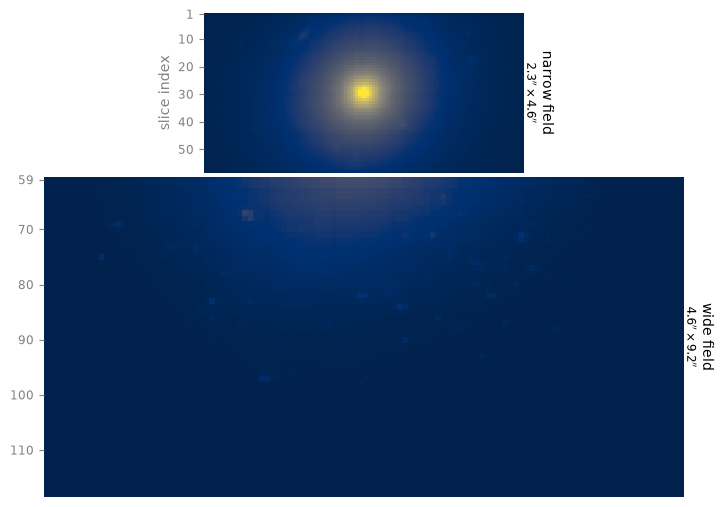

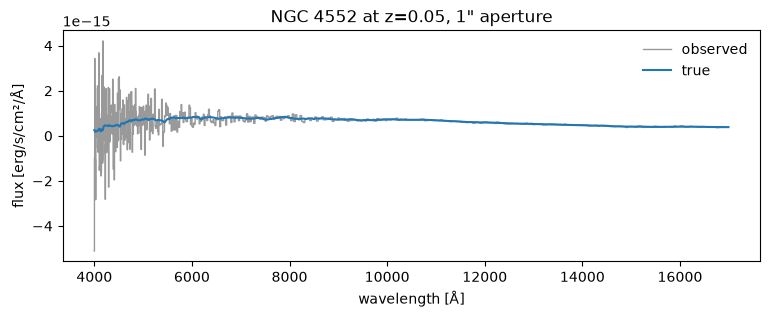

In [2]:
galaxy = slicersim.LazuliGalaxy(redshift=0.05, model="ngc4552")

(cube_narrow, _), (cube_wide, _) = galaxy.get_cube(which="both", switch_off=SKY)
fig = galaxy.show_cube((cube_narrow, cube_wide), lbda_range=[6000, 9000])

config, snr = galaxy.setup_to_snr(10, **snr_range)
print(config, f"SNR={snr:.1f}, exposure time: {galaxy.get_exposure_time():.0f} s")

lbda, flux, variance = galaxy.get_spectrum(unit="flambda")
fig, ax = plt.subplots(figsize=(9, 3))
ax.plot(lbda, flux, color="0.6", lw=1, ds="steps-mid", label="observed")
ax.plot(lbda, galaxy.get_spectrum(unit="flambda", incl_error=False)[1], color="C0", label="true")
ax.set(xlabel="wavelength [Å]", ylabel="flux [erg/s/cm²/Å]", title="NGC 4552 at z=0.05, 1\" aperture")
ax.legend(frameon=False)
# At z=0.05, NGC 4552 is bright (magabs=-21 by default, i.e. r~16): SNR=10 within 1" takes less
# than a minute. At this redshift 1" is ~1 kpc: the narrow field (2.3" x 4.6") only covers the core
# of the galaxy, and the wide field, right below it, its outskirts.

### 5.2 — The kilonova in its host

Add the kilonova, 1" from the core of NGC 4552. Show the narrow-field image, marking the
kilonova and the host center, with and without the host. What exposure time is needed to reach SNR=10 on the kilonova?
Compare with the same kilonova without host.

*Hint: `LazuliKilonova(redshift=0.05, phase=1.4, theta=30, host="ngc4552")`, then
`change_properties(pointsource__position=...)`; `"host"` can be added to `switch_off`.*

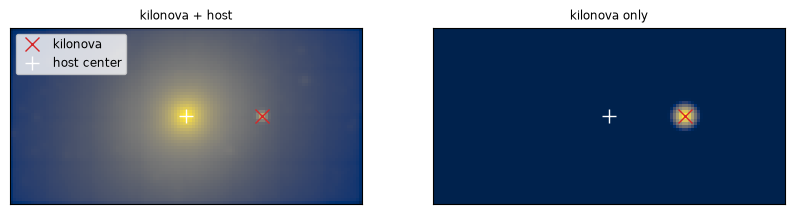

 in NGC 4552: {'nmd': (11, 4, 0), 'nramps': 1}, SNR=10.5, exposure time: 125 s


     no host: {'nmd': (11, 4, 0), 'nramps': 1}, SNR=10.6, exposure time: 125 s


In [3]:
kilonova = slicersim.LazuliKilonova(redshift=0.05, phase=1.4, theta=30, host="ngc4552")
kilonova.change_properties(pointsource__position=(25, 0))   # 1" = 25 spaxels of 0.04"

fig, axes = plt.subplots(1, 2, figsize=(10, 3))
for ax, (title, switch_off) in zip(axes, [("kilonova + host", SKY), 
                                          ("kilonova only", SKY + ["host"])]):
    cube, _ = kilonova.get_cube(which="narrow", switch_off=switch_off)
    ny, nx = cube.shape[1:]
    ax.imshow(cube.sum(axis=0), origin="lower", cmap="cividis", norm="asinh")
    ax.plot((nx - 1) / 2 + 25, (ny - 1) / 2, "x", color="C3", ms=10, label="kilonova")
    ax.plot((nx - 1) / 2, (ny - 1) / 2, "+", color="w", ms=10, label="host center")
    ax.set_title(title, fontsize="small"); ax.set_xticks([]); ax.set_yticks([])
axes[0].legend(fontsize="small", loc="upper left")
plt.show()

no_host = slicersim.LazuliKilonova(redshift=0.05, phase=1.4, theta=30)
no_host.change_properties(pointsource__position=(25, 0))
for label, target in [("in NGC 4552", kilonova), ("no host", no_host)]:
    config, snr = target.setup_to_snr(10, **snr_range)
    print(f"{label:>12s}: {config}, SNR={snr:.1f}, exposure time: {target.get_exposure_time():.0f} s")
# The kilonova is invisible on top of the galaxy core in the image, but 1" from the core the host does
# not change the exposure time: the PSF is small, and little galaxy light falls under the kilonova.

### 5.3 — On the core

Kilonovae are not always in the outskirts of their host. With the readout found in 5.2 (with
the host), compute the SNR per wavelength bin and the host share of the variance for the
kilonova on the core, 0.5", 1" and 2" away from it.

*Hint: `target.simulation.get_band_variance_contribution(**snr_range)` returns `"snr"` and
`"frac_host"` (notebook 07).*

In [4]:
print("readout:", kilonova.get_readout_config())   # from 5.2
for distance in [0, 0.5, 1, 2]:   # [arcsec]
    kilonova.change_properties(pointsource__position=(distance / 0.04, 0))
    budget = kilonova.simulation.get_band_variance_contribution(**snr_range)
    print(f"{distance:3.1f}\" from the core: SNR per bin={budget['snr']:.2f}, host share {budget['frac_host']:.0%}")
# On the core, the host dominates the variance (~70%) and the SNR drops from ~6.9 to ~3.9 per bin.
# From 0.5" on, it is only a few percent: the host matters within a few PSF widths of its core.

readout: {'nmd': (11, 4, 0), 'nramps': 1}


0.0" from the core: SNR per bin=3.88, host share 69%


0.5" from the core: SNR per bin=6.75, host share 7%


1.0" from the core: SNR per bin=6.92, host share 2%


2.0" from the core: SNR per bin=6.98, host share 0%


### 5.4 — A fast transient

A kilonova fades in days. For phases 1.4, 3, 5 and 7 days after the merger, find the exposure
time needed to reach SNR=10 for the kilonova on the core and 1" away. Plot them against the
phase. What does the host cost, and when?

*Hint: `change_properties(phase=...)`, then `setup_to_snr()`.*

0" from the core: 1.4 d: 4 min, 3 d: 5 min, 5 d: 24 min, 7 d: 169 min


1" from the core: 1.4 d: 2 min, 3 d: 2 min, 5 d: 4 min, 7 d: 9 min


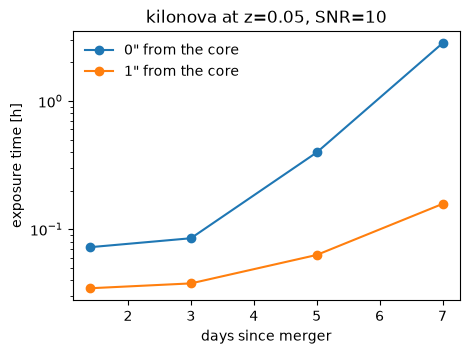

In [5]:
phases = [1.4, 3, 5, 7]
fig, ax = plt.subplots(figsize=(5, 3.5))
for distance in [0, 1]:   # [arcsec]
    kilonova.change_properties(pointsource__position=(distance / 0.04, 0))
    exptimes = []
    for phase in phases:
        kilonova.change_properties(phase=phase)
        _ = kilonova.setup_to_snr(10, **snr_range)
        exptimes.append(kilonova.get_exposure_time())
    print(f"{distance}\" from the core:", ", ".join(f"{p} d: {t/60:.0f} min" for p, t in zip(phases, exptimes)))
    ax.plot(phases, np.asarray(exptimes) / 3600, "o-", label=f"{distance}\" from the core")

ax.set(xlabel="days since merger", ylabel="exposure time [h]", yscale="log", title="kilonova at z=0.05, SNR=10")
ax.legend(frameon=False)
# The kilonova fades while the host stays. 1" from the core, the exposure time grows from 2 to 9 min
# between 1.4 and 7 days; on the core, from 4 min to ~3 h, ~20 times more than 1" away at 7 days.
# The later the follow-up, the more a kilonova on its host core costs.

### 5.5 — The kilonova and the galaxy light underneath

Put the kilonova on the core, 3 days after the merger, with the readout giving SNR=10. Plot,
in erg/s/cm²/Å, the kilonova spectrum (optimal extraction) and the host spectrum within 0.1"
of the kilonova. Which one dominates, and where?

*Hint: store the aperture with `change_properties(aperture="0.1-arcsec", aperture__position=...)`;
then `get_spectrum(of_host=True, method="aperture")` extracts the host within it (notebook 08).
Compare with the kilonova light within the same aperture: `get_spectrum(method="aperture")`.*

{'nmd': (27, 4, 0), 'nramps': 1} exposure time: 5 min


4000-6000 Å: host / kilonova within 0.1" = 12.68
6000-9000 Å: host / kilonova within 0.1" = 14.83
9000-13000 Å: host / kilonova within 0.1" = 17.87
13000-17000 Å: host / kilonova within 0.1" = 19.95


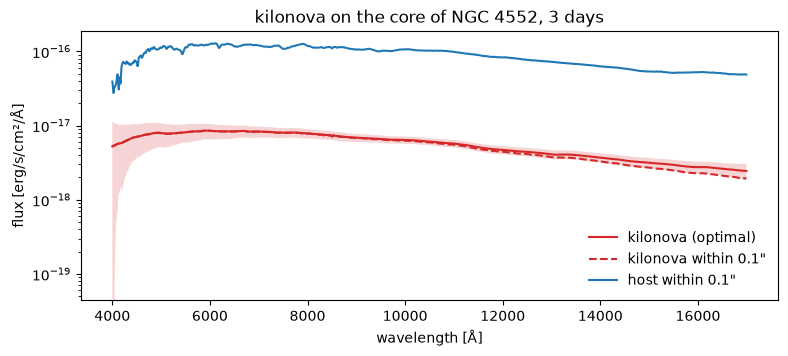

In [6]:
kilonova.change_properties(pointsource__position=(0, 0), phase=3)
_ = kilonova.setup_to_snr(10, **snr_range)
print(kilonova.get_readout_config(), f"exposure time: {kilonova.get_exposure_time() / 60:.0f} min")

kilonova.change_properties(aperture="0.1-arcsec", aperture__position=(0, 0))   # on the kilonova
lbda, flux_kn, var_kn = kilonova.get_spectrum(unit="flambda", incl_error=False)        # optimal
_, flux_kn_ap, _ = kilonova.get_spectrum(unit="flambda", incl_error=False, method="aperture")
_, flux_host, _ = kilonova.get_spectrum(unit="flambda", incl_error=False, of_host=True, method="aperture")

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.plot(lbda, flux_kn, color="C3", label="kilonova (optimal)")
ax.fill_between(lbda, flux_kn - np.sqrt(var_kn), flux_kn + np.sqrt(var_kn), color="C3", alpha=0.2, lw=0)
ax.plot(lbda, flux_kn_ap, color="C3", ls="--", label="kilonova within 0.1\"")
ax.plot(lbda, flux_host, color="C0", label="host within 0.1\"")
ax.set(xlabel="wavelength [Å]", ylabel="flux [erg/s/cm²/Å]", yscale="log", title="kilonova on the core of NGC 4552, 3 days")
ax.legend(frameon=False)

ratio = flux_host / flux_kn_ap
for lmin, lmax in [(4000, 6000), (6000, 9000), (9000, 13_000), (13_000, 17_000)]:
    band = (lbda > lmin) & (lbda < lmax)
    print(f"{lmin}-{lmax} Å: host / kilonova within 0.1\" = {np.nanmedian(ratio[band]):.2f}")
# Within 0.1" of the core, the host is 13 to 20 times brighter than the kilonova, more in the red
# (the old stellar population of the elliptical is redder than the kilonova at 3 days). SNR=10 is
# still reached in 5 min: the optimal extraction fits the PSF and the host only adds photon noise.
# The real difficulty is to subtract the host light underneath, e.g. with a reference observation
# taken once the kilonova has faded.